In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [2]:
%cd ~/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot

/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot


In [3]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

def add_time(da):
    # single dummy time step, year 1 -> function maps the SH copy to year 2,
    # so the two halves never share a timestamp
    t = [cftime.Datetime360Day(1, 1, 1)]
    return da.expand_dims(time=t)          # dims: (time: 1, pfull, lat, lon)

def hemispheric_mean(da):
    da = add_time(da)                      # add missing time dim
    da = flip_and_append(da)               # NH + mirrored SH, stacked along time
    return da.mean("time")                 # average the two hemispheres

In [4]:
#import DATA
ucomp_ASYM = hemispheric_mean(xr.open_dataset("~/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/uvt_clim_2-51.nc")['ucomp'])
temp_ASYM = hemispheric_mean(xr.open_dataset("~/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/uvt_clim_2-51.nc")['temp'])
ucomp_SYM = hemispheric_mean(xr.open_dataset("~/DATA/isca_data/exeter_project_mf_baseline_KS/tot/uvt_clim_2-51.nc")['ucomp'])
temp_SYM = hemispheric_mean(xr.open_dataset("~/DATA/isca_data/exeter_project_mf_baseline_KS/tot/uvt_clim_2-51.nc")['temp'])

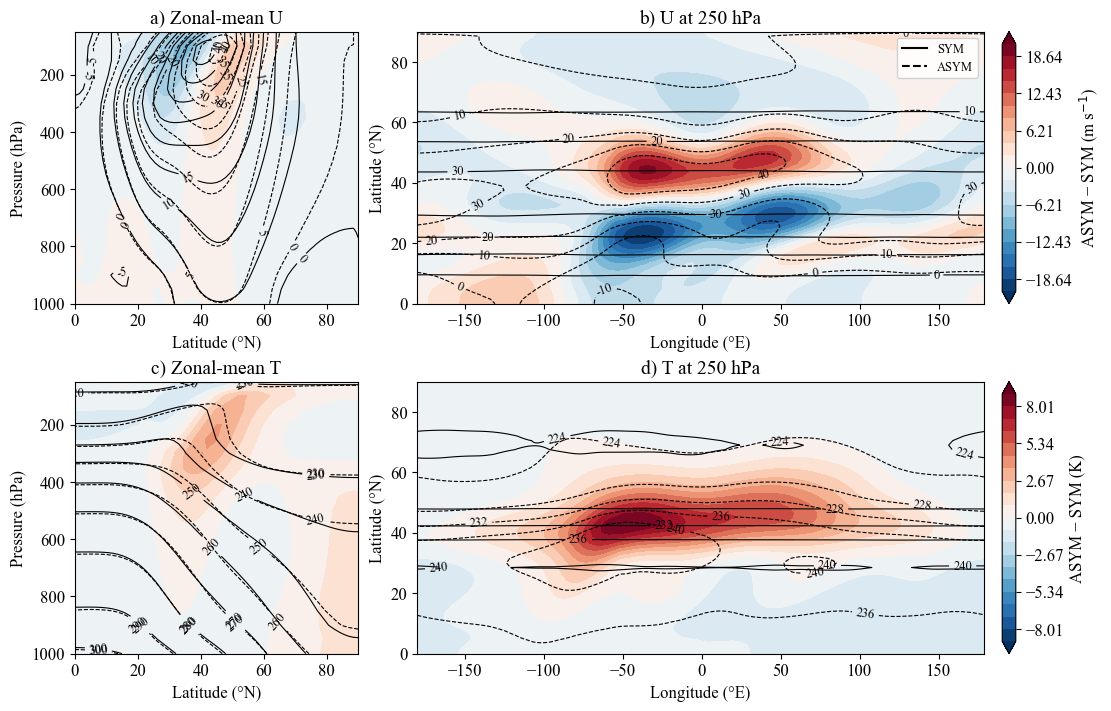

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plev=250

# ---------- helpers ----------
def sym_levels(*das, n=21):
    vmax = max(float(np.nanmax(np.abs(d))) for d in das)
    return np.linspace(-vmax, vmax, n)

def step_levels(arrs, step):
    lo = np.floor(min(float(a.min()) for a in arrs) / step) * step
    hi = np.ceil(max(float(a.max()) for a in arrs) / step) * step
    return np.arange(lo, hi + step, step)

def auto_levels(arrs, n_target=15):
    """Contour levels with a 'nice' step (1, 2, 5 x 10^k) giving ~n_target lines."""
    lo = min(float(a.min()) for a in arrs)
    hi = max(float(a.max()) for a in arrs)
    raw = (hi - lo) / n_target
    mag = 10 ** np.floor(np.log10(raw))
    step = min([1, 2, 5, 10], key=lambda s: abs(s * mag - raw)) * mag
    return step_levels(arrs, step)

def draw(ax, x, y, sym, asym, diff, cont_levels, diff_levels, cmap, title,
         xlabel, ylabel):
    cf = ax.contourf(x, y, diff, levels=diff_levels, cmap=cmap, extend="both")
    cs_sym  = ax.contour(x, y, sym,  levels=cont_levels, colors="k",
                         linewidths=0.8, linestyles="solid")
    cs_asym = ax.contour(x, y, asym, levels=cont_levels, colors="k",
                         linewidths=0.8, linestyles="dashed")
    # inline labels
    for cs in (cs_sym, cs_asym):
        ax.clabel(cs, inline=True, inline_spacing=3, fontsize=9, fmt="%g")
    ax.set_title(title, loc="center", fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return cf

# ---------- config ----------
# step_* = fixed contour spacing; None -> automatic (~n_auto lines)
fields = {
    "u": dict(sym=ucomp_SYM, asym=ucomp_ASYM, cmap="RdBu_r", unit="m s$^{-1}$",
              name="U", step_zm=5,  step_map=10),
    "t": dict(sym=temp_SYM,  asym=temp_ASYM,  cmap="RdBu_r", unit="K",
              name="T", step_zm=10, step_map=4),   # finer, automatic for panel d
}
n_auto = 15   # target number of contour lines when step is None

# ---------- plot ----------
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 2]})

for row, key in enumerate(["u", "t"]):
    f = fields[key]
    sym, asym = f["sym"], f["asym"]

    sym_zm, asym_zm = sym.mean("lon"), asym.mean("lon")
    diff_zm = asym_zm - sym_zm

    sym_p  = sym.sel(pfull=plev, method="nearest")
    asym_p = asym.sel(pfull=plev, method="nearest")
    diff_p = asym_p - sym_p

    # shading shared across the row
    diff_levels = sym_levels(diff_zm, diff_p)

    # contour levels chosen independently per panel
    lev_zm  = step_levels([sym_zm, asym_zm], f["step_zm"])
    lev_map = (step_levels([sym_p, asym_p], f["step_map"])
               if f["step_map"] else auto_levels([sym_p, asym_p], n_auto))

    ax0 = axes[row, 0]
    draw(ax0, sym_zm.lat, sym_zm.pfull, sym_zm, asym_zm, diff_zm,
         lev_zm, diff_levels, f["cmap"],
         f"{'ac'[row]}) Zonal-mean {f['name']}",
         "Latitude (°N)", "Pressure (hPa)")
    ax0.invert_yaxis()

    ax1 = axes[row, 1]
    cf1 = draw(ax1, sym_p.lon, sym_p.lat, sym_p, asym_p, diff_p,
               lev_map, diff_levels, f["cmap"],
               f"{'bd'[row]}) {f['name']} at {plev} hPa",
               "Longitude (°E)", "Latitude (°N)")

    cbar = fig.colorbar(cf1, ax=axes[row, :], orientation="vertical",
                        fraction=0.025, pad=0.02)
    cbar.set_label(f"ASYM − SYM ({f['unit']})")

handles = [Line2D([0], [0], color="k", ls="-",  label="SYM"),
           Line2D([0], [0], color="k", ls="--", label="ASYM")]
axes[0, 1].legend(handles=handles, loc="upper right", fontsize=9, framealpha=0.9)

plt.savefig("/home/links/mf671/github/lwa_persistence/scripts_supplementary_figures/PLOTS/asym_vs_sym_circ_diff.png", dpi=200)
plt.show()